In [ ]:
import numpy as np
states = [np.load(f'/home/shadadan/NeuGen/data/matsynth_scene_state/{81} frames/btf_frame__{i:04d}.npy', allow_pickle=True).item() for i in range(81)]
to_world = states[0]['sensor.to_world']
light_position = np.asarray(states[0]['area_light_sphere.to_world'])[:3, -1, 0]

import sys
sys.path.append('/home/shadadan/NeuGen/src')

In [2]:
spp = 1
jitter = False
repeat = 1

In [ ]:
import torch
import imageio.v3 as iio


from torch_renderer import (
    Plane,
    Texture,
    create_camera_from_mitsuba,
    DiffuseBRDF,
    render,
)

# User-configurable parameters (formerly argparse)
texture = "/home/shadadan/NeuGen/notebooks/table.png"
out = "render_soft.png"
width = 512
height = 512
# focal_mm = 35.0
sensor_w_mm = 36.0
sensor_h_mm = 24.0
eye = [0.0, 0.0, 7]
at = [0.0, 0.0, 0.0]
up = [0.0, 1.0, 0.0]
# light = [0.0, 0.0, 6]
light_intensity = 40.1685
device = "cuda"

fov = 37.0
device = torch.device(device)

# Geometry
plane_width = 4.0
plane_height = 4.0
plane = Plane.create(width=plane_width, height=plane_height, device=device)

# Camera (Mitsuba-like sensor)
import numpy as np

# Build Mitsuba-style to_world from eye/at/up
_eye = torch.tensor(eye, dtype=torch.float32, device=device)
_at = torch.tensor(at, dtype=torch.float32, device=device)
_up = torch.tensor(up, dtype=torch.float32, device=device)
_forward = torch.nn.functional.normalize(_at - _eye, dim=0)
_right = torch.nn.functional.normalize(torch.cross(_forward, _up, dim=0), dim=0)
_up_vec = torch.nn.functional.normalize(torch.cross(_right, _forward, dim=0), dim=0)
_to_world = torch.eye(4, dtype=torch.float32, device=device)
_to_world[:3, 0] = -_right  # Mitsuba s-axis (left)
_to_world[:3, 1] = _up_vec  # Mitsuba t-axis (up)
_to_world[:3, 2] = _forward  # Mitsuba n-axis (view dir)
_to_world[:3, 3] = _eye



sensor = {
    "fov": fov,  # allow overriding via fov
    "resolution": (height, width),
    "to_world": to_world,
}
camera = create_camera_from_mitsuba(sensor, device=device)

# BRDF
brdf = DiffuseBRDF(reflectance=texture, device=device, srgb=True)

# Render
apply_filter = True
filter_stddev = 0.5
filter_radius = 2.0

seed = 0


# iio.imwrite(out, (image.cpu().numpy() * 255).astype("uint8"))
# print(f"Saved {out}")




/home/shadadan/miniconda3/envs/neugen/lib/python3.13/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [4]:
light_position

array([4., 0., 6.])

In [5]:
for i in range(repeat):

        outputs = render(
            camera=camera,
        plane=plane,
        brdf=brdf,
        image_size=(height, width),
        light_position=torch.tensor(light_position.tolist(), dtype=torch.float32, device=device),
        light_intensity=torch.tensor([light_intensity]*3, dtype=torch.float32, device=device),
        apply_filter=apply_filter,
        filter_stddev=filter_stddev,
        filter_radius=filter_radius,
        spp=spp,
        jitter=jitter,
        seed=seed,
    )

image_torch = outputs["image"]
visibility_torch = outputs["visibility"]
uv_torch = outputs["uv"]
uv_torch = torch.cat([uv_torch, torch.zeros_like(uv_torch)[...,0:1]], dim=-1)
albedo_reflectance_torch = outputs["albedo"]
cam_dir_torch = outputs["cam_dir"]
light_dir_torch = outputs["light_dir"]


In [6]:
# scene_dict['sensor']

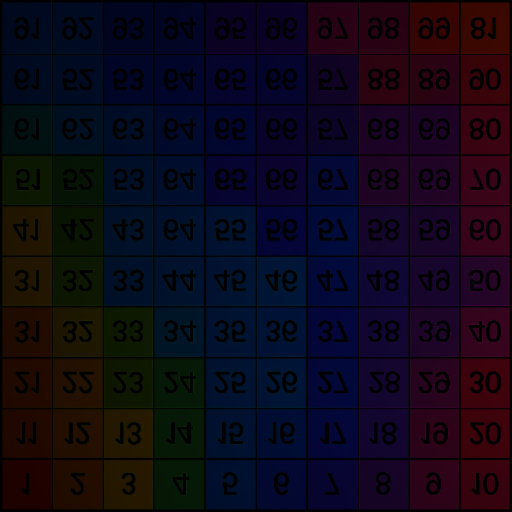

In [7]:
from PIL import Image
Image.fromarray((image_torch.cpu().numpy() * 255).astype('uint8'))

In [8]:
import mitsuba as mi
import drjit as dr
mi.set_variant('cuda_ad_rgb')
from typing import Tuple, List, Any, Optional
import drjit as dr
import gc


class CenterPixelSamplerIntegrator(mi.python.ad.integrators.common.ADIntegrator):
    # this integrator inherits from the mitsuba built-in ADIntegrator with one difference, 
    # it disables the random offset for antialising and only samples from the center of the pixel
    def sample_rays(
        self,
        scene: mi.Scene,
        sensor: mi.Sensor,
        sampler: mi.Sampler,
    ) -> Tuple[mi.RayDifferential3f, mi.Spectrum, mi.Vector2f, mi.Float]:
        """
        Sample a 2D grid of primary rays for a given sensor

        Returns a tuple containing

        - the set of sampled rays
        - a ray weight (usually 1 if the sensor's response function is sampled
          perfectly)
        - the continuous 2D image-space positions associated with each ray
        """
        film = sensor.film()
        film_size = film.crop_size()
        rfilter = film.rfilter()
        border_size = rfilter.border_size()

        if film.sample_border():
            film_size += 2 * border_size

        spp = sampler.sample_count()
        assert jitter or spp == 1 #NOTE: We assume 1 spp for now

        # Compute discrete sample position
        idx = dr.arange(mi.UInt32, dr.prod(film_size) * spp)

        # Try to avoid a division by an unknown constant if we can help it
        log_spp = dr.log2i(spp)
        if 1 << log_spp == spp:
            idx >>= dr.opaque(mi.UInt32, log_spp)
        else:
            idx //= dr.opaque(mi.UInt32, spp)

        # Compute the position on the image plane
        pos = mi.Vector2i()
        pos.y = idx // film_size[0]
        pos.x = dr.fma(mi.UInt32(mi.Int32(-film_size[0])), pos.y, idx)

        if film.sample_border():
            pos -= border_size

        pos += mi.Vector2i(film.crop_offset())

        # Cast to floating point and add random offset
        pos_f = mi.Vector2f(pos) + 0.5                    #NOTE: other than 1spp, the only difference to mitsuba built-in code is here, instead of random offset, we sample the center of the pixel
        if jitter:
            pos_f += sampler.next_2d() - 0.5
            print(jitter)
            
        # Re-scale the position to [0, 1]^2
        scale = dr.rcp(mi.ScalarVector2f(film.crop_size()))
        offset = -mi.ScalarVector2f(film.crop_offset()) * scale
        pos_adjusted = dr.fma(pos_f, scale, offset)

        aperture_sample = mi.Vector2f(0.0)
        if sensor.needs_aperture_sample():
            aperture_sample = sampler.next_2d()

        time = sensor.shutter_open()
        if sensor.shutter_open_time() > 0:
            time += sampler.next_1d() * sensor.shutter_open_time()

        wavelength_sample = 0
        if mi.is_spectral:
            wavelength_sample = sampler.next_1d()

        with dr.resume_grad():
            ray, weight = sensor.sample_ray_differential(
                time=time,
                sample1=wavelength_sample,
                sample2=pos_adjusted,
                sample3=aperture_sample
            )

        # With box filter, ignore random offset to prevent numerical instabilities
        splatting_pos = mi.Vector2f(pos) if rfilter.is_box_filter() else pos_f

        return ray, weight, splatting_pos


In [9]:
len(to_world[0])

4

In [10]:
spp

1

In [11]:

import numpy as np
import sys

sys.path.append('/home/shadadan/NeuGen/src')

from render import *


renderer =StreamingBTFRenderer(resolution=512, grid_size=4, only_center_mesh_instance=True, arealight=False)
# scene = renderer.scene_template
# params = renderer.params_template
scene_dict = renderer.scene_dict
# params['light.position'] = [0.0, 0.0, 6.0]
scene_dict['my_shape_group']['material_plane']['bsdf'] = mi.load_dict({'type': 'diffuse', 'reflectance': 
#{'type': 'rgb', 'value': [0.8, 0.8, 0.8]}})
 {'type': 'bitmap', 'filename': texture,
                        'wrap_mode': 'mirror',
                        'filter_type': 'bilinear'
}})

scene_dict['sensor']['to_world'] =  mi.ScalarTransform4f().look_at(origin=eye,target=at,up=up)
# scene_dict['sensor']['to_world'] = mi.Transform4f(np.asarray(to_world))
scene_dict['light']['intensity'] = light_intensity
scene_dict['light']['position'] = light_position

scene = mi.load_dict(scene_dict)

params = mi.traverse(scene)

params['sensor.to_world'] = mi.Transform4f(np.asarray(to_world))

params.update()

direct_integraotr = mi.load_dict({'type': 'direct', 'bsdf_samples': 0, 'emitter_samples': 1})

class VisibilityIntegrator(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        si:mi.SurfaceInteraction3f = scene.ray_intersect(ray, mi.RayFlags.All, True, active)
        valid_ray = active & si.is_valid()
        result = dr.select(valid_ray, mi.Vector3f(1), mi.Vector3f(0))
        return result, active, [], None


class UVIntegrator(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        si:mi.SurfaceInteraction3f = scene.ray_intersect(ray, mi.RayFlags.All, True, active)
        valid_ray = active & si.is_valid()
        uv = np.concatenate([si.uv.numpy(), np.zeros_like(si.uv.numpy())[0:1]], axis=0)
        print(uv.shape)
        result = dr.select(valid_ray, mi.Vector3f(uv), mi.Vector3f(0))
        return result, active, [], None

class AlbedoIntegrator(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        si:mi.SurfaceInteraction3f = scene.ray_intersect(ray, mi.RayFlags.All, True, active)
        valid_ray = active & si.is_valid()

        result = si.bsdf().eval_diffuse_reflectance(si, active)

        result = dr.select(valid_ray, result, mi.Vector3f(0))
        return result, active, [], None



class CamRayIntegrator(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        si:mi.SurfaceInteraction3f = scene.ray_intersect(ray, mi.RayFlags.All, True, active)
        valid_ray = active & si.is_valid()
        result = dr.select(valid_ray, ray.d, mi.Vector3f(0))
        return result, active, [], None

class LightRayIntegrator(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        si:mi.SurfaceInteraction3f = scene.ray_intersect(ray, mi.RayFlags.All, True, active)
        result = mi.Spectrum(0.0)

        # NEE
        ctx = mi.BSDFContext()
        bsdf = si.bsdf(ray)
        flags = bsdf.flags()
        active = active & si.is_valid()

        sample_emitter = active & mi.has_flag(flags, mi.BSDFFlags.Smooth)

        active_e = sample_emitter
        (ds, emitter_val) = scene.sample_emitter_direction(si, sampler.next_2d(active_e), True, active_e)
        active_e = active & (ds.pdf != 0.0)

        result = dr.select(active_e, ds.d, mi.Vector3f(0))

        return result, active, [], None


class LightIntegrator(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        si:mi.SurfaceInteraction3f = scene.ray_intersect(ray, mi.RayFlags.All, True, active)
        result = mi.Spectrum(0.0)

        # NEE
        ctx = mi.BSDFContext()
        bsdf = si.bsdf(ray)
        flags = bsdf.flags()
        active = active & si.is_valid()

        sample_emitter = active & mi.has_flag(flags, mi.BSDFFlags.Smooth)

        active_e = sample_emitter
        (ds, emitter_val) = scene.sample_emitter_direction(si, sampler.next_2d(active_e), True, active_e)
        active_e = active & (ds.pdf != 0.0)

        result = dr.select(active_e, emitter_val, mi.Vector3f(0))

        return result, active, [], None



class direct(CenterPixelSamplerIntegrator):
    def sample(self,
               mode: dr.ADMode,
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               depth: mi.UInt32,
               δL ,
               δaovs ,
               state_in,
               active: mi.Bool):

        result , active , _ = direct_integraotr.sample(scene, sampler, ray,  None ,active)

        return result, active, [], None




visibility_integrator = VisibilityIntegrator(mi.Properties())
direct_center_integrator = direct(mi.Properties())
uv_integrator = UVIntegrator(mi.Properties())
albedo_integrator = AlbedoIntegrator(mi.Properties())
cam_ray_integrator = CamRayIntegrator(mi.Properties())
light_ray_integrator = LightRayIntegrator(mi.Properties())
light_ray_integrator = LightRayIntegrator(mi.Properties())
light_integrator = LightIntegrator(mi.Properties())


BTF sensor loaded successfully
Clamped path integrator registered successfully
Initializing BTF renderer on GPU 0 with resolution: 512x512
Estimated texture memory per material: 0.01 GB
Creating base mesh with 4x4 vertices...
Base size: 4.0
X range: [-2.00, 2.00], width: 4.00
Y range: [-2.00, 2.00], height: 4.00
Base mesh created: /tmp/tmpxisb7q_h.obj
0: i=0,j=0 -> world y(top)=2.000000, y(bottom)=-2.000000
Scene template created with 3x3 mixed mirror/rotation pattern
  - Tile spacing: 4.000 (overlap: 0.0%)
  - Pattern: 1 instances with varied transformations

:
  instance_mixed_0.to_world
  light.sampling_weight
  light.position
  light.intensity.value
  my_shape_group.material_plane.bsdf.brdf_0.clearcoat.value
  my_shape_group.material_plane.bsdf.brdf_0.clearcoat_gloss.value
  my_shape_group.material_plane.bsdf.brdf_0.metallic.data
  my_shape_group.material_plane.bsdf.brdf_0.metallic.to_uv
  my_shape_group.material_plane.bsdf.brdf_0.main_specular_sampling_rate
  my_shape_group.materi

In [12]:
print(params['light.intensity.value'])
print(params['light.position'])
print(light_position)
print(light_intensity)


[40.1685]
[[4, 0, 6]]
[4. 0. 6.]
40.1685


In [13]:
image_mi = (mi.render(scene, integrator = direct_center_integrator, spp = spp))
mi.Bitmap(image_mi)

Bitmap[
  pixel_format = rgb,
  component_format = float32,
  size = [512, 512],
  srgb_gamma = 0,
  struct = Struct<12>[
    float32 R; // @0, premultiplied alpha
    float32 G; // @4, premultiplied alpha
    float32 B; // @8, premultiplied alpha
  ],
  data = [ 3 MiB of image data ]
]

In [14]:
visibility_mi = (mi.render(scene, integrator = visibility_integrator, spp = spp))
visibility_mi = visibility_mi.numpy()[:,:,0:1]
uv_mi = (mi.render(scene, integrator = uv_integrator, spp = spp))
albedo_mi = (mi.render(scene, integrator = albedo_integrator, spp = spp))
cam_ray_mi = (mi.render(scene, integrator = cam_ray_integrator, spp = spp))
light_dir_mi = (mi.render(scene, integrator = light_ray_integrator, spp = spp))



(3, 262144)


In [15]:
params

SceneParameters[
  ---------------------------------------------------------------------------------------------------------------
  Name                                                        Flags    Type              Parent
  ---------------------------------------------------------------------------------------------------------------
  instance_mixed_0.to_world                                            Transform4f       Instance
  light.sampling_weight                                                float             PointLight
  light.position                                                       Point3f           PointLight
  light.intensity.value                                       ∂        Float             UniformSpectrum
  my_shape_group.material_plane.bsdf.reflectance.data         ∂        TensorXf          BitmapTextureImpl
  my_shape_group.material_plane.bsdf.reflectance.to_uv                 ScalarTransform3f BitmapTextureImpl
  my_shape_group.material_plane.silhouette

In [16]:
dr.enable_grad(params['my_shape_group.material_plane.bsdf.reflectance.data'])

spp = 256
jitter = True
for i in range(repeat):
    image_mi_grad = (mi.render(scene, integrator = direct_integraotr, params = params, spp = spp))

    loss = dr.mean(dr.sqr(image_mi_grad - 10000))
    dr.backward(loss)
    mi_grad = dr.grad(params['my_shape_group.material_plane.bsdf.reflectance.data'])
    


/tmp/ipykernel_2617357/2572522332.py:8: DeprecationWarning: sqr() is deprecated, please use square(arg)
  loss = dr.mean(dr.sqr(image_mi_grad - 10000))


In [17]:
for i in range(repeat):
    brdf.albedo.texture.requires_grad = True

    outputs = render(
        camera=camera,
        plane=plane,
        brdf=brdf,
        image_size=(height, width),
        light_position=torch.tensor(light_position.tolist(), dtype=torch.float32, device=device),
        light_intensity=torch.tensor([light_intensity]*3, dtype=torch.float32, device=device),
        apply_filter=apply_filter,
        filter_stddev=filter_stddev,
        filter_radius=filter_radius,
        spp=spp,
        jitter=jitter,
        seed=seed,
    )

    image_torch_grad = outputs["image"]

    (image_torch_grad-10000).square().mean().backward()
    torch_grad = brdf.albedo.texture.grad
    torch_grad


In [18]:
(torch_grad - mi_grad.torch()).abs().mean()

tensor(9.6709e-05, device='cuda:0')

In [19]:
# print(mi.Bitmap(mi_img.numpy()))

In [20]:
maps = {'image': [image_mi, image_torch], 'uv': [uv_mi, uv_torch], 'visibility': [visibility_mi, visibility_torch], 'albedo': [albedo_mi, albedo_reflectance_torch], 'cam_dir': [cam_ray_mi, cam_dir_torch], 'light_dir': [light_dir_mi, light_dir_torch], 'grad': [mi_grad, torch_grad]}

for key, value in maps.items():
    a = np.array(value[0])
    b = np.array(value[1].cpu())
    # print(key)
    # print(a.shape, b.shape)
    # print(b.shape)
    print(key, np.abs(a - b).mean(), np.allclose(a, b, atol=1e-3))

    if key == 'grad':
        a = np.abs(a)*100
        b = np.abs(b)*100
    mi.Bitmap(a).write(f'{key}_mi.exr')
    mi.Bitmap(b).write(f'{key}_torch.exr')

/tmp/ipykernel_2617357/2911528086.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  b = np.array(value[1].cpu())


image 1.896776e-05 True
uv 3.3547276e-05 False
visibility 0.000100620746 False
albedo 9.483748e-05 False
cam_dir 4.6916233e-05 False
light_dir 5.1092706e-05 False
grad 9.670886e-05 True


In [21]:
torch_grad

tensor([[[-0.0005, -0.0005, -0.0005],
         [-0.0006, -0.0006, -0.0006],
         [-0.0006, -0.0006, -0.0006],
         ...,
         [-0.0015, -0.0015, -0.0015],
         [-0.0013, -0.0013, -0.0013],
         [-0.0014, -0.0014, -0.0014]],

        [[-0.0006, -0.0006, -0.0006],
         [-0.0008, -0.0008, -0.0008],
         [-0.0008, -0.0008, -0.0008],
         ...,
         [-0.0016, -0.0016, -0.0016],
         [-0.0015, -0.0015, -0.0015],
         [-0.0015, -0.0015, -0.0015]],

        [[-0.0006, -0.0006, -0.0006],
         [-0.0008, -0.0008, -0.0008],
         [-0.0009, -0.0009, -0.0009],
         ...,
         [-0.0019, -0.0019, -0.0019],
         [-0.0015, -0.0015, -0.0015],
         [-0.0014, -0.0014, -0.0014]],

        ...,

        [[-0.0005, -0.0005, -0.0005],
         [-0.0008, -0.0008, -0.0008],
         [-0.0008, -0.0008, -0.0008],
         ...,
         [-0.0014, -0.0014, -0.0014],
         [-0.0017, -0.0017, -0.0017],
         [-0.0016, -0.0016, -0.0016]],

        [[

In [ ]:
image.mean()

NameError: name 'image' is not defined

: 

In [ ]:
mi_img.torch().mean()

tensor(0.1535, device='cuda:0')

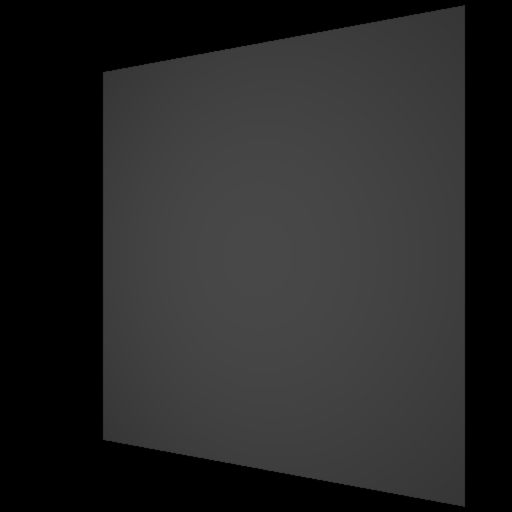

In [ ]:
from PIL import Image
Image.fromarray((mi_img.torch().cpu().numpy() * 255).astype('uint8'))

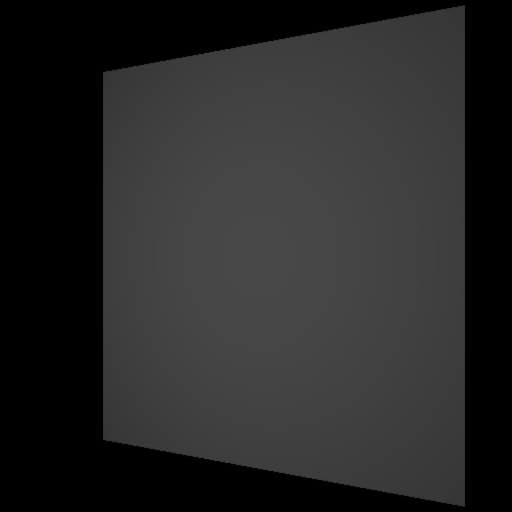

In [ ]:
Image.fromarray((image.cpu().numpy() * 255).astype('uint8'))

In [ ]:
scene.sensors()

[PerspectiveCamera[
   x_fov = [37],
   near_clip = 0.01,
   far_clip = 10000,
   film = HDRFilm[
     size = [512, 512],
     crop_size = [512, 512],
     crop_offset = [0, 0],
     sample_border = 0,
     compensate = 0,
     filter = GaussianFilter[stddev=0.50, radius=2.00],
     file_format = OpenEXR,
     pixel_format = rgb,
     component_format = float32,
   ],
   sampler = IndependentSampler[
     base_seed = 0
     sample_count = 4
     samples_per_wavefront = 1
     wavefront_size = 0
   ],
   resolution = [512, 512],
   shutter_open = 0,
   shutter_open_time = 0,
   to_world = [[-0.83205, -7.53629e-17, -0.5547, 4],
               [0, 1, -1.35862e-16, 9.79717e-16],
               [0.5547, -1.13044e-16, -0.83205, 6],
               [0, 0, 0, 1]]
 ]]